# BikeFlow

## 1.Predicting Bike Rental Demand in Seoul


The purpose of this project is to investigate whether machine learning can predict hourly bike rental demand in Seoul based on weather conditions and time-related factors.

The dataset contains 8,760 hourly observations from December 2017 to November 2018.

To enrich the original dataset, historical cloud cover data was collected from the Open-Meteo API and matched to the bike rental observations using date and hour.

### Business question

Can we predict hourly bike rental demand to support better capacity planning?

Machine learning approach

This is a supervised learning problem using regression, since the target variable, Rented Bike Count, is a numerical value.

The project will compare Linear Regression and Random Forest Regressor to evaluate which approach produces more accurate predictions.

In [1]:
# Import Pandas for data manipulation
import pandas as pd

# Import NumPy for numerical calculations
import numpy as np

# Import Matplotlib for visualizations
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Import Requests for downloading data from APIs
import requests

In [2]:

# Read and enrich our data
df = pd.read_csv("data/bikeflow_enriched.csv")

# Size of data set
print("Dataset shape:", df.shape)

# 5 first rows
display(df.head())

Dataset shape: (8760, 16)


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,datetime,cloud_cover
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00,0
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00,0
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00,0
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00,0
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00,0


### External Data Integration – Open-Meteo API

To investigate whether additional weather information could improve bike rental predictions, historical hourly cloud cover data was retrieved from the Open-Meteo Archive API.

The weather observations were matched with the Seoul Bike Sharing dataset using hourly timestamps in the `Asia/Seoul` time zone.

**Data Validation**

During the initial API integration, the datasets were inspected for their dimensions, missing values, and timestamp alignment. The merge was validated as a one-to-one relationship to prevent duplicate matches.

All 8,760 bike rental observations were successfully matched with cloud cover data, with no missing values in the new feature.

**Reproducibility**

The API integration is implemented as a reusable Python function. Both the downloaded weather data and the enriched bike rental dataset are saved as CSV files, allowing the analysis to be reproduced without repeated API requests.

Cloud cover was evaluated as an additional model feature, but it did not produce a meaningful improvement in Random Forest cross-validation performance.

In [3]:

# Define a reusable function to download and merge weather data
def fetch_and_merge_weather_data():

    # Load the original bike rental dataset
    bike_df = pd.read_csv(
        "data/SeoulBikeData.csv",
        encoding="latin1"
    )

    # Convert the original date strings to datetime values
    bike_df["Date"] = pd.to_datetime(
        bike_df["Date"],
        format="%d/%m/%Y"
    )

    # Combine date and hour into a timestamp
    bike_df["datetime"] = (
        bike_df["Date"] + pd.to_timedelta(bike_df["Hour"], unit="h")
    )

    # Define the historical weather API endpoint
    url = "https://archive-api.open-meteo.com/v1/archive"

    # Configure the API request for Seoul and the dataset period
    params = {
        "latitude": 37.5665,
        "longitude": 126.9780,
        "start_date": bike_df["Date"].min().strftime("%Y-%m-%d"),
        "end_date": bike_df["Date"].max().strftime("%Y-%m-%d"),
        "hourly": "cloud_cover",
        "timezone": "Asia/Seoul"
    }

    # Send the request to Open-Meteo
    response = requests.get(url, params=params, timeout=60)

    # Stop the function if the API returns an HTTP error
    response.raise_for_status()

    # Convert the JSON response into a DataFrame
    weather_df = pd.DataFrame(response.json()["hourly"])

    # Convert API timestamps to datetime values
    weather_df["datetime"] = pd.to_datetime(weather_df["time"])

    # Merge the original bike data with the weather observations
    bike_final = pd.merge(
        bike_df,
        weather_df[["datetime", "cloud_cover"]],
        on="datetime",
        how="left",
        validate="one_to_one"
    )

    # Check that every bike observation has matching weather data
    if bike_final["cloud_cover"].isna().any():
        raise ValueError(
            "Some bike observations have no matching cloud cover data."
        )

    # Save the downloaded weather observations
    weather_df.to_csv("data/open_meteo_seoul.csv", index=False)

    # Save the enriched bike rental dataset
    bike_final.to_csv("data/bikeflow_enriched.csv", index=False)

    # Show a summary of the merged dataset
    print("Total bike observations:", len(bike_final))
    print(
        "Matched cloud cover observations:",
        bike_final["cloud_cover"].notna().sum()
    )

    # Return the enriched dataset
    return bike_final


## 2. Data Understanding & Quality Checks

Before cleaning or modeling, we inspect the dataset's structure, data types, and completeness.

In [4]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names, data types and non-null counts
df.info()

Dataset shape: (8760, 16)
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 n

In [5]:

# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Count completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# Count duplicated timestamps
print("Duplicate timestamps:", df["datetime"].duplicated().sum())


Missing values per column:
Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
datetime                     0
cloud_cover                  0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0


In [6]:

# Convert datetime from text (str) to pandas datetime
df["datetime"] = pd.to_datetime(df["datetime"])

# Sort observations chronologically (oldest first). Important due to training modell on the oldest dates.
df = df.sort_values("datetime").reset_index(drop=True)

# Check the data type after conversion
print("Data type:", df["datetime"].dtype)

# Check the first and last timestamps
print("First timestamp:", df["datetime"].min())
print("Last timestamp:", df["datetime"].max())


Data type: datetime64[us]
First timestamp: 2017-12-01 00:00:00
Last timestamp: 2018-11-30 23:00:00


### 2.1 Data Quality Summary

The dataset contains 8,760 hourly observations and 16 columns. No missing values, duplicate rows, or duplicate timestamps were found.

The datetime column is converted to a proper datetime format, and the observations are sorted chronologically to prepare for time series analysis and modeling.

In [7]:

# Create a complete hourly timeline between the first and last timestamp
expected_hours = pd.date_range(
    start=df["datetime"].min(),  # First timestamp in our dataset
    end=df["datetime"].max(),    # Last timestamp in our dataset
    freq="h"                     # One timestamp per hour
)

# Find timestamps that should exist but are missing from the dataset
missing_hours = expected_hours.difference(df["datetime"])

# Display the results
print("Expected hours:", len(expected_hours))
print("Actual rows:", len(df))
print("Missing hours:", len(missing_hours))


Expected hours: 8760
Actual rows: 8760
Missing hours: 0


In [8]:

# Display descriptive statistics for all numerical columns
df.describe().T


,count,mean,min,25%,50%,75%,max,std
Rented Bike Count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
Hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
Temperature(°C),8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
Humidity(%),8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
Wind speed (m/s),8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
Visibility (10m),8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
Dew point temperature(°C),8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
Solar Radiation (MJ/m2),8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
Rainfall(mm),8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193
Snowfall (cm),8760.0,0.075068,0.0,0.0,0.0,0.0,8.8,0.436746


In [9]:

# Count hours with zero bike rentals
print("Zero bike rentals:", (df["Rented Bike Count"] == 0).sum())

# Count hours with zero humidity
print("Zero humidity:", (df["Humidity(%)"] == 0).sum())

# Count hours with rainfall greater than zero
print("Hours with rain:", (df["Rainfall(mm)"] > 0).sum())

# Count hours with snowfall greater than zero
print("Hours with snow:", (df["Snowfall (cm)"] > 0).sum())


Zero bike rentals: 295
Zero humidity: 17
Hours with rain: 528
Hours with snow: 443


In [10]:

# Compare zero rentals with whether the bike rental system was operating
pd.crosstab(
    df["Functioning Day"],        # Rows: operating status (Yes/No)
    df["Rented Bike Count"] == 0,  # Columns: True if rentals equal zero
    margins=True                  # Add totals for rows and columns
)


Rented Bike Count,False,True,All
Functioning Day,,,
No,0,295,295
Yes,8465,0,8465
All,8465,295,8760


## 2.2 Zero Rentals and Operational Status

A cross-tabulation revealed that all 295 observations with zero bike rentals occurred when the bike rental system was not functioning (`Functioning Day = No`).

The remaining 8,465 observations represent hours when the system was operating, and all have positive rental counts.

Since the objective is to predict rental demand during operating hours, non-functioning periods will be excluded from the modeling dataset. The original dataset will be preserved.

This decision also avoids zero target values when calculating MAPE. However, MAPE will still be interpreted cautiously, particularly for hours with low rental counts.

In [11]:

# Keep the original dataset unchanged
# Select only hours when the rental system was operating
df_model = df[df["Functioning Day"] == "Yes"].copy()

# Check the number of observations
print("Original dataset:", df.shape)
print("Modeling dataset:", df_model.shape)


Original dataset: (8760, 16)
Modeling dataset: (8465, 16)


In [12]:

# Select rows where humidity is exactly zero
zero_humidity = df[df["Humidity(%)"] == 0]

# Display relevant columns to investigate these observations
zero_humidity[
    [
        "datetime",
        "Temperature(°C)",
        "Humidity(%)",
        "Dew point temperature(°C)",
        "Rainfall(mm)",
        "cloud_cover",
        "Functioning Day"
    ]
]


,datetime,Temperature(°C),Humidity(%),Dew point temperature(°C),Rainfall(mm),cloud_cover,Functioning Day
4063,2018-05-19 07:00:00,11.4,0,4.5,0.0,0,Yes
4106,2018-05-21 02:00:00,13.9,0,-2.1,0.0,92,Yes
4107,2018-05-21 03:00:00,13.0,0,-2.5,0.0,27,Yes
4108,2018-05-21 04:00:00,12.4,0,-3.4,0.0,19,Yes
4109,2018-05-21 05:00:00,11.9,0,-2.7,0.0,0,Yes
4110,2018-05-21 06:00:00,11.4,0,-2.0,0.0,0,Yes
4111,2018-05-21 07:00:00,12.3,0,-2.7,0.0,0,Yes
4131,2018-05-22 03:00:00,15.5,0,10.4,0.0,75,Yes
4132,2018-05-22 04:00:00,15.6,0,10.5,0.0,100,Yes
4133,2018-05-22 05:00:00,15.7,0,10.6,0.0,100,Yes


In [13]:

# Select observations from May 22, between 00:00 and 09:00
humidity_check = df[
    (df["datetime"] >= "2018-05-22 00:00:00") &
    (df["datetime"] <= "2018-05-22 09:00:00")
]

# Compare humidity, temperature and dew point over consecutive hours
humidity_check[
    [
        "datetime",
        "Temperature(°C)",
        "Humidity(%)",
        "Dew point temperature(°C)"
    ]
]


,datetime,Temperature(°C),Humidity(%),Dew point temperature(°C)
4128,2018-05-22 00:00:00,16.0,71,10.7
4129,2018-05-22 01:00:00,15.9,71,10.6
4130,2018-05-22 02:00:00,15.7,74,11.0
4131,2018-05-22 03:00:00,15.5,0,10.4
4132,2018-05-22 04:00:00,15.6,0,10.5
4133,2018-05-22 05:00:00,15.7,0,10.6
4134,2018-05-22 06:00:00,15.5,0,10.4
4135,2018-05-22 07:00:00,16.3,69,10.5
4136,2018-05-22 08:00:00,18.2,63,11.0
4137,2018-05-22 09:00:00,19.3,62,11.8


In [14]:

# Keep the original humidity values for comparison
df_model["Humidity_original"] = df_model["Humidity(%)"]

# Mark suspicious zero humidity values as missing
df_model["Humidity(%)"] = df_model["Humidity(%)"].replace(0, float("nan"))

# Use datetime as a temporary index for time-based interpolation
df_model = df_model.set_index("datetime")

# Estimate missing humidity values using surrounding timestamps
df_model["Humidity(%)"] = df_model["Humidity(%)"].interpolate(method="time")

# Restore datetime as a regular column
df_model = df_model.reset_index()

# Display corrected observations
df_model.loc[
    df_model["Humidity_original"] == 0,
    ["datetime", "Humidity_original", "Humidity(%)"]
]


,datetime,Humidity_original,Humidity(%)
4015,2018-05-19 07:00:00,0,63.500000
4058,2018-05-21 02:00:00,0,30.857143
4059,2018-05-21 03:00:00,0,30.714286
4060,2018-05-21 04:00:00,0,30.571429
4061,2018-05-21 05:00:00,0,30.428571
4062,2018-05-21 06:00:00,0,30.285714
4063,2018-05-21 07:00:00,0,30.142857
4083,2018-05-22 03:00:00,0,73.000000
4084,2018-05-22 04:00:00,0,72.000000
4085,2018-05-22 05:00:00,0,71.000000


In [15]:

# Check whether any humidity values are still missing
print("Missing humidity values:", df_model["Humidity(%)"].isna().sum())

# Check the minimum and maximum humidity after interpolation
print("Minimum humidity:", df_model["Humidity(%)"].min())
print("Maximum humidity:", df_model["Humidity(%)"].max())

# Check that the original dataset is unchanged
print("Zero humidity values in original data:", (df["Humidity(%)"] == 0).sum())


Missing humidity values: 0
Minimum humidity: 10.0
Maximum humidity: 98.0
Zero humidity values in original data: 17


## 2.3 Humidity Data Quality

Seventeen observations contained zero relative humidity, all occurring in May 2018. Comparison with nearby observations and dew point temperatures indicated that these values were likely recording errors.

The suspicious values were replaced with missing values and estimated using time-based interpolation for exploratory analysis. The original dataset was preserved.

Because time-based interpolation can use future observations, the preprocessing approach will be reviewed before cross-validation and final model evaluation to prevent data leakage.

# 3. Exploratory Data Analysis (EDA)

The purpose of EDA is to understand the distribution of bike rentals, identify patterns and relationships between variables, and investigate potential outliers before training machine learning models.

## 3.1 Distribution of Bike Rentals

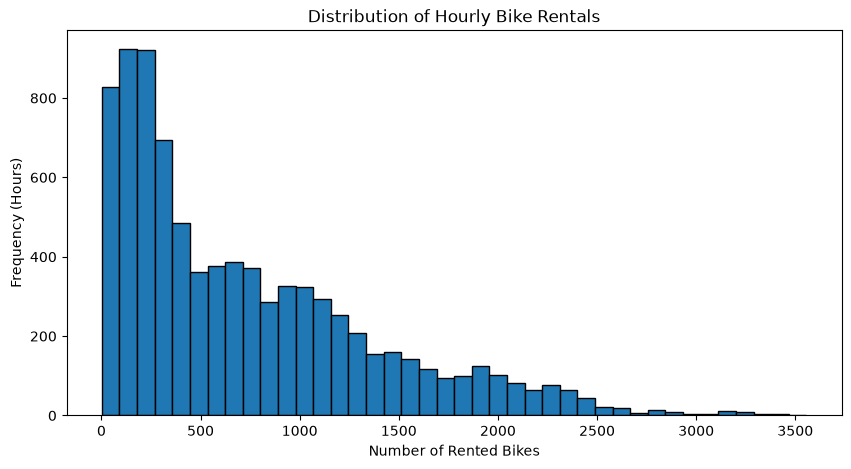

In [16]:

# Import matplotlib for data visualization
import matplotlib.pyplot as plt

# Create a histogram of hourly bike rentals
plt.figure(figsize=(10, 5))

# Divide rental counts into 40 intervals (bins) 89 ish bikes per bin
plt.hist(df_model["Rented Bike Count"], bins=40, edgecolor="black")

# Add chart title and axis labels
plt.title("Distribution of Hourly Bike Rentals")
plt.xlabel("Number of Rented Bikes")
plt.ylabel("Frequency (Hours)")

# Display the chart
plt.show()


/var/folders/87/4p21wf8x54z_3r2h977m5ps00000gn/T/ipykernel_7681/3753461780.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_model["Rented Bike Count"], vert=False)


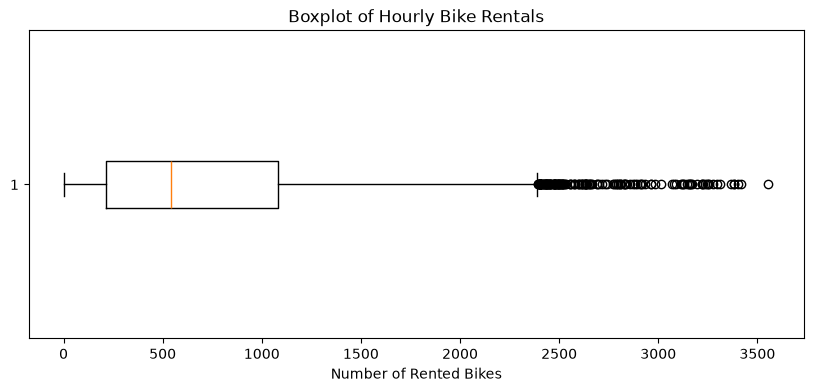

In [17]:

# Create a boxplot to examine the distribution and potential outliers
plt.figure(figsize=(10, 4))

# Show the distribution of hourly bike rentals
plt.boxplot(df_model["Rented Bike Count"], vert=False)

# Add a title and label
plt.title("Boxplot of Hourly Bike Rentals")
plt.xlabel("Number of Rented Bikes")

# Display the chart
plt.show()


In [18]:

# Select the 10 hours with the highest number of bike rentals
top_rentals = df_model.nlargest(10, "Rented Bike Count")

# Display relevant columns to investigate high-demand hours
top_rentals[
    [
        "datetime",
        "Rented Bike Count",
        "Hour",
        "Temperature(°C)",
        "Rainfall(mm)",
        "Seasons",
        "Holiday"
    ]
]


,datetime,Rented Bike Count,Hour,Temperature(°C),Rainfall(mm),Seasons,Holiday
4770,2018-06-19 18:00:00,3556,18,24.1,0.0,Summer,No Holiday
4818,2018-06-21 18:00:00,3418,18,27.8,0.0,Summer,No Holiday
4602,2018-06-12 18:00:00,3404,18,24.9,0.0,Summer,No Holiday
4794,2018-06-20 18:00:00,3384,18,27.0,0.0,Summer,No Holiday
4410,2018-06-04 18:00:00,3380,18,24.4,0.0,Summer,No Holiday
4842,2018-06-22 18:00:00,3365,18,29.3,0.0,Summer,No Holiday
4506,2018-06-08 18:00:00,3309,18,26.2,0.0,Summer,No Holiday
6762,2018-09-10 18:00:00,3298,18,25.9,0.0,Autumn,No Holiday
6930,2018-09-17 18:00:00,3277,18,25.3,0.0,Autumn,No Holiday
6810,2018-09-12 18:00:00,3256,18,27.0,0.0,Autumn,No Holiday


## 3.2 Average Bike Rentals by Hour

We investigate how average bike rental demand varies throughout the day to identify possible daily patterns and peak hours.

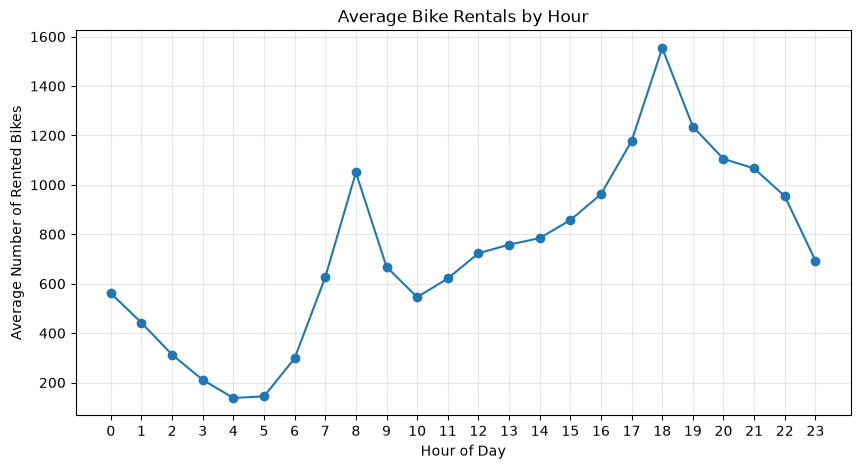

In [19]:
# Calculate average bike rentals for each hour of the day
hourly_rentals = df_model.groupby("Hour")["Rented Bike Count"].mean()

# Create a line chart
plt.figure(figsize=(10, 5))

# Plot the average rentals for each hour
plt.plot(hourly_rentals.index, hourly_rentals.values, marker="o")

# Add chart title and axis labels
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rented Bikes")

# Show every hour on the X-axis
plt.xticks(range(24))

# Add a grid to make the chart easier to read
plt.grid(alpha=0.3)

# Display the chart
plt.show()


In [20]:
df_model.groupby("Hour")["Rented Bike Count"].mean()

Hour
0      561.457386
1      441.923295
2      312.769886
3      210.840909
4      137.488636
5      144.218750
6      298.184659
7      626.606232
8     1050.229462
9      667.943343
10     545.764873
11     621.277620
12     723.218130
13     758.172805
14     784.620397
15     857.373938
16     962.257790
17    1177.212465
18    1554.016997
19    1235.776204
20    1105.303116
21    1066.512748
22     954.167139
23     693.940510
Name: Rented Bike Count, dtype: float64

**EDA Finding – Hourly Rental Patterns**

Average bike rental demand shows two distinct peaks: one at 08:00 and a larger peak at 18:00. The lowest demand occurs around 04:00–05:00.

This pattern may be associated with morning and evening commuting. Demand also increases gradually during the afternoon before reaching its highest level at 18:00.

These findings suggest that the hour of the day is an important potential predictor of bike rental demand.

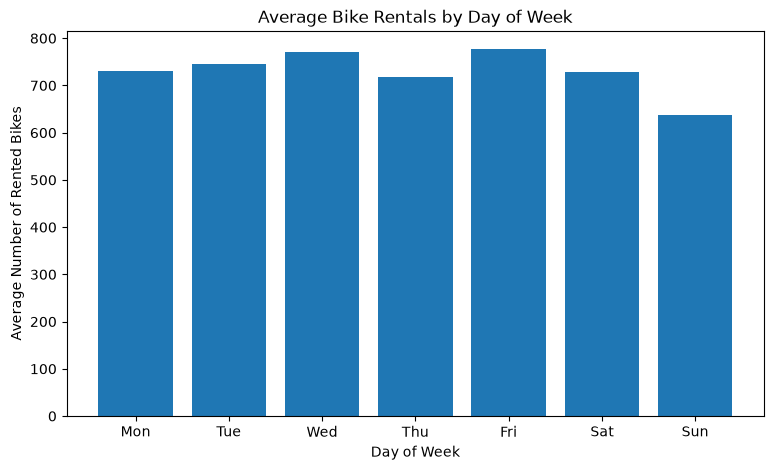

In [21]:

# Extract the day of the week from datetime
# Monday = 0, Tuesday = 1, ..., Sunday = 6
df_model["day_of_week"] = df_model["datetime"].dt.dayofweek

# Calculate average rentals for each day of the week
daily_rentals = df_model.groupby("day_of_week")["Rented Bike Count"].mean()

# Create a bar chart
plt.figure(figsize=(9, 5))

# Display average rentals for Monday through Sunday
plt.bar(
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    daily_rentals.reindex(range(7))
)

# Add title and labels
plt.title("Average Bike Rentals by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Number of Rented Bikes")

# Display the chart
plt.show()


## 3.3 Weekday vs Weekend – Hourly Rental Patterns

We compare hourly rental patterns on weekdays and weekends to investigate whether demand differs throughout the day.

This may help us identify commuting-related patterns and determine whether day of week should be included as a feature in our machine learning models.

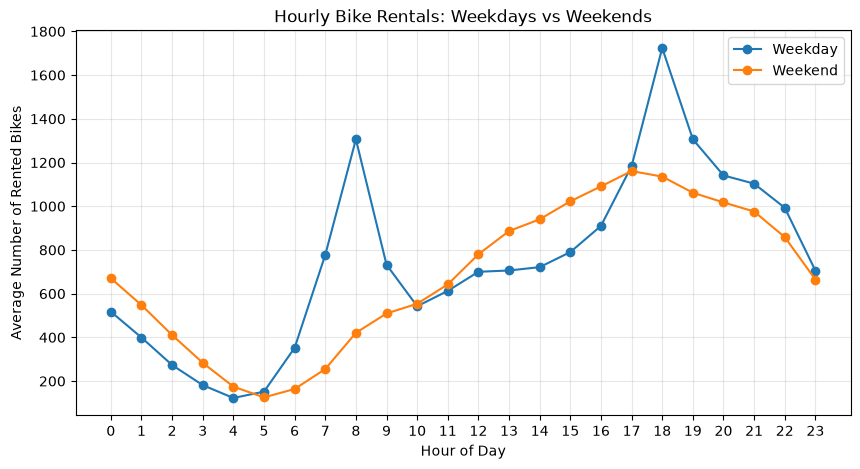

In [22]:

# Create a column identifying weekdays and weekends
# Monday = 0, ..., Friday = 4, Saturday = 5, Sunday = 6
df_model["day_type"] = df_model["day_of_week"].apply(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate average bike rentals for each hour and day type
hourly_by_day_type = (
    df_model.groupby(["Hour", "day_type"])["Rented Bike Count"]
    .mean()
    .unstack()
)

# Create a line chart
plt.figure(figsize=(10, 5))

# Plot average weekday rentals
plt.plot(
    hourly_by_day_type.index,
    hourly_by_day_type["Weekday"],
    marker="o",
    label="Weekday"
)

# Plot average weekend rentals
plt.plot(
    hourly_by_day_type.index,
    hourly_by_day_type["Weekend"],
    marker="o",
    label="Weekend"
)

# Add chart information
plt.title("Hourly Bike Rentals: Weekdays vs Weekends")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Rented Bikes")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

# Display the chart
plt.show()


**EDA Finding – Weekday vs Weekend Patterns**

Hourly bike rental patterns differ substantially between weekdays and weekends.

On weekdays, demand shows two distinct peaks at 08:00 and 18:00, potentially reflecting commuting patterns. On weekends, the morning peak disappears, and demand increases more gradually, reaching its highest level around 17:00.

Weekend demand is generally higher during the afternoon (approximately 12:00–16:00) and during the early nighttime hours (00:00–04:00).

These findings suggest that hour of day and day type may interact when predicting bike rental demand. This relationship will be considered during feature engineering and model comparison.

### 3.3.1 Statistical Hypothesis Test – Weekdays vs Weekends

To investigate whether bike rental demand differs between weekdays and weekends, a Welch's independent samples t-test is performed.

Hourly rental counts are aggregated into daily totals before testing, reducing the dependence between observations from the same day.

**Hypotheses**

- **H₀:** Mean daily bike rentals are equal on weekdays and weekends.
- **H₁:** Mean daily bike rentals differ between weekdays and weekends.

The significance level is set to α = 0.05.

Welch's t-test is used because it does not assume equal variances between the two groups. However, potential temporal dependence between consecutive days remains a limitation.

In [65]:
# Import Welch's independent samples t-test
from scipy.stats import ttest_ind

# Keep only observations from days when bike rental services were operating
test_df = df[df["Functioning Day"] == "Yes"].copy()

# Convert the datetime column to a daily date
test_df["day"] = pd.to_datetime(test_df["datetime"]).dt.date

# Aggregate hourly rentals into daily totals
daily_rentals = (
    test_df.groupby("day")
    .agg(
        total_rentals=("Rented Bike Count", "sum"),
        hours_observed=("Rented Bike Count", "size")
    )
    .reset_index()
)

# Keep only days with all 24 hourly observations
daily_rentals = daily_rentals[daily_rentals["hours_observed"] == 24].copy()

# Identify weekends: Saturday = 5 and Sunday = 6
daily_rentals["is_weekend"] = pd.to_datetime(
    daily_rentals["day"]
).dt.dayofweek >= 5

# Separate weekday and weekend rental totals
weekday_rentals = daily_rentals.loc[
    ~daily_rentals["is_weekend"], "total_rentals"
]

weekend_rentals = daily_rentals.loc[
    daily_rentals["is_weekend"], "total_rentals"
]

# Perform Welch's t-test without assuming equal group variances
t_stat, p_value = ttest_ind(
    weekday_rentals,
    weekend_rentals,
    equal_var=False
)

# Display descriptive statistics and test results
print("Weekday days:", len(weekday_rentals))
print("Weekend days:", len(weekend_rentals))
print("Weekday mean daily rentals:", round(weekday_rentals.mean(), 2))
print("Weekend mean daily rentals:", round(weekend_rentals.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", p_value)

Weekday days: 251
Weekend days: 101
Weekday mean daily rentals: 17954.69
Weekend mean daily rentals: 16333.16
T-statistic: 1.3893
P-value: 0.16639697337404813


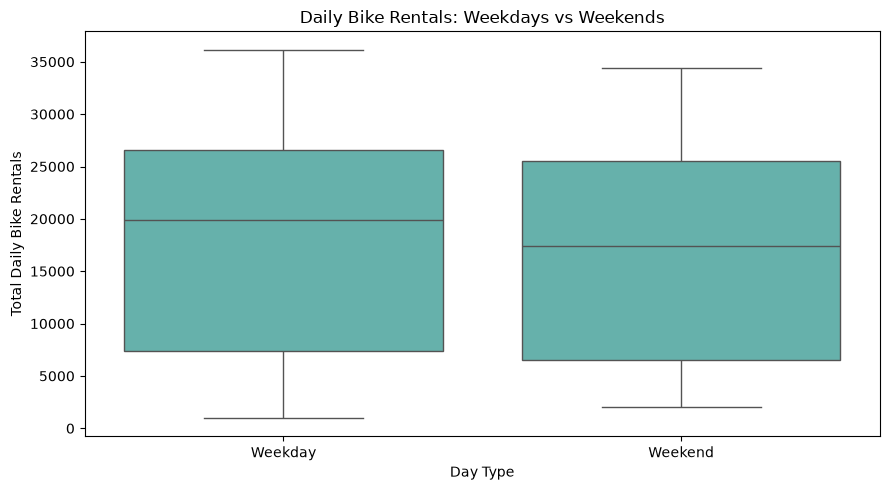

In [66]:
# Create labels for weekdays and weekends
daily_rentals["day_type"] = np.where(
    daily_rentals["is_weekend"],
    "Weekend",
    "Weekday"
)

# Create a boxplot to compare daily rental distributions
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=daily_rentals,
    x="day_type",
    y="total_rentals",
    order=["Weekday", "Weekend"],
    color="#59BDB5"
)

# Add descriptive chart labels
plt.title("Daily Bike Rentals: Weekdays vs Weekends")
plt.xlabel("Day Type")
plt.ylabel("Total Daily Bike Rentals")

# Improve the layout
plt.tight_layout()
plt.show()

**Statistical Test Finding – Weekdays vs Weekends**

Weekdays had a higher observed mean daily rental count (17,954.69) than weekends (16,333.16). However, Welch's t-test did not identify a statistically significant difference between the groups (t = 1.3893, p = 0.1664).

Since the p-value exceeds the significance level of 0.05, the null hypothesis cannot be rejected.

The boxplot shows substantial variability and overlapping distributions between weekdays and weekends, supporting the observation that daily rental volumes are not clearly separated.

Although total daily rentals were not significantly different, the EDA revealed distinct hourly demand patterns. Weekdays showed pronounced commuting peaks, while weekend demand was distributed differently throughout the day.

This suggests that the timing of demand may be more informative than the weekday–weekend difference in daily totals.

The test is exploratory, and temporal dependence between days may affect the reliability of the p-value.

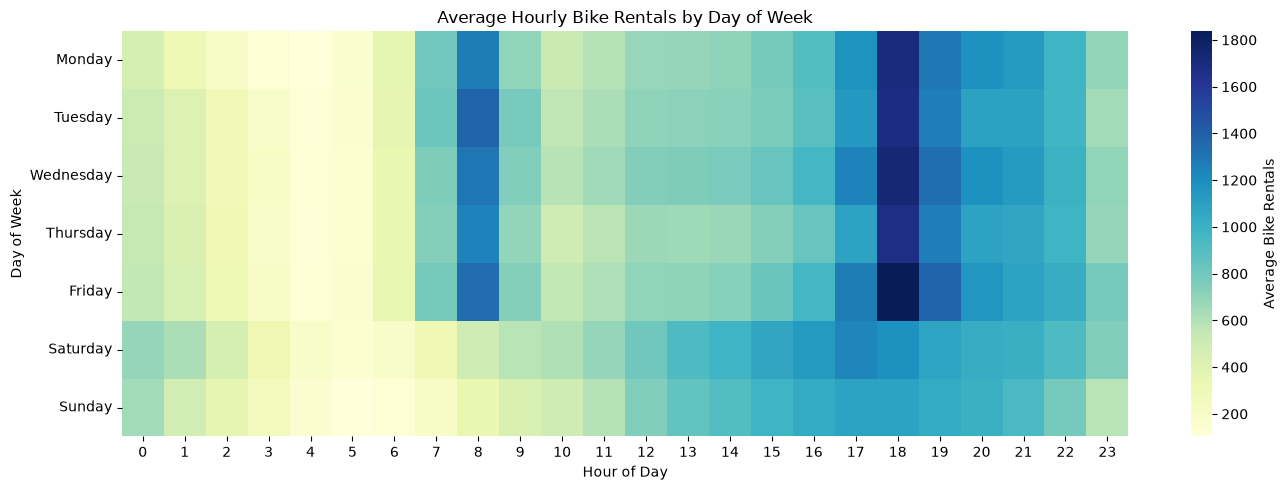

In [23]:

# Create a copy containing only operational observations
heatmap_df = df[df["Functioning Day"] == "Yes"].copy()

# Extract the day of week from the datetime column
# Monday = 0, Sunday = 6
heatmap_df["day_of_week"] = heatmap_df["datetime"].dt.dayofweek

# Calculate average bike rentals for each weekday and hour
hourly_weekday_demand = heatmap_df.pivot_table(
    index="day_of_week",          # Rows represent weekdays
    columns="Hour",               # Columns represent hours (0-23)
    values="Rented Bike Count",   # Values to aggregate
    aggfunc="mean"                # Calculate average rentals
)

# Replace weekday numbers with readable names
hourly_weekday_demand.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Create the heatmap
plt.figure(figsize=(14, 5))

sns.heatmap(
    hourly_weekday_demand,
    cmap="YlGnBu",                # Yellow = lower, blue = higher demand
    cbar_kws={"label": "Average Bike Rentals"}
)

# Add labels and title
plt.title("Average Hourly Bike Rentals by Day of Week")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")

# Display the chart
plt.tight_layout()
plt.show()


**EDA Finding – Hourly Demand Across the Week**

The heatmap confirms that bike rental demand follows distinct patterns across the week.

From Monday to Friday, demand consistently peaks around 08:00 and 18:00–19:00, suggesting a strong association with commuting hours. On weekends, the morning peak is largely absent, and rentals are distributed more evenly throughout the afternoon.

The visualization highlights an interaction between hour of day and day type: the same hour can have substantially different rental demand depending on whether it is a weekday or weekend.

**Business implication:** These patterns could support more effective bike allocation by identifying periods when higher rental activity is expected.

**Modeling implication:** Both `Hour` and `is_weekend` are relevant candidate features. Their interaction may also be worth exploring in future model improvements.

## 3.4 Correlation Analysis

A correlation matrix is used to examine linear relationships between numerical variables.

The analysis focuses on identifying potential predictors of bike rental demand and detecting strong correlations between explanatory variables.

Correlation does not imply causation, and nonlinear relationships may not be fully captured by Pearson correlation.

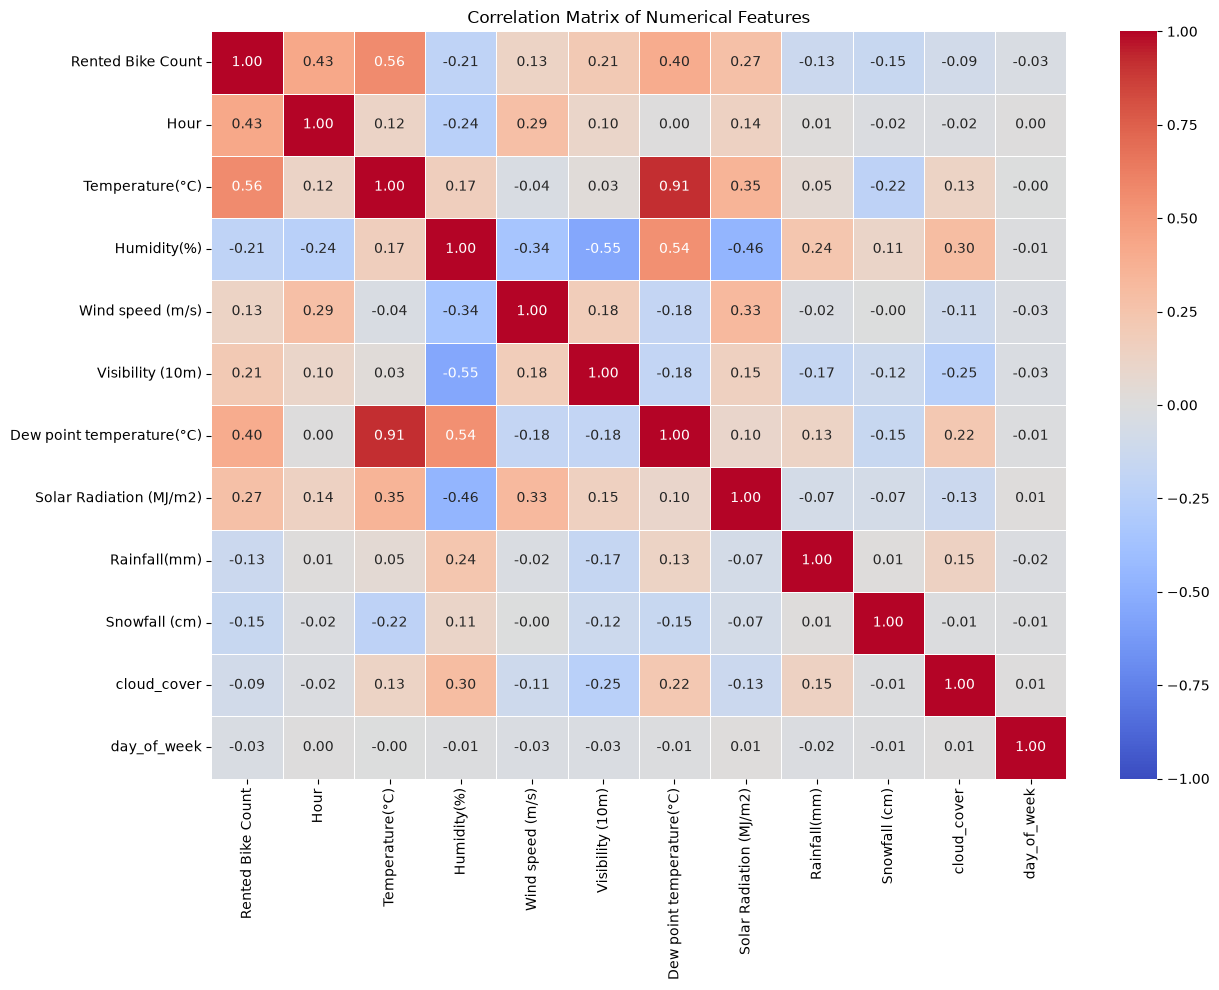

In [24]:

# Select numerical columns for correlation analysis
numeric_df = df_model.select_dtypes(include="number")

# Exclude the original humidity column used only for quality control
numeric_df = numeric_df.drop(columns=["Humidity_original"])

# Calculate the Pearson correlation matrix
correlation_matrix = numeric_df.corr()

# Import seaborn for statistical visualizations
import seaborn as sns

# Create a figure
plt.figure(figsize=(13, 10))

# Create a correlation heatmap
sns.heatmap(
    correlation_matrix,  # Our calculated Pearson correlations
    annot=True,          # Display correlation values in each cell
    fmt=".2f",           # Show two decimal places
    cmap="coolwarm",     # Blue = negative, red = positive
    vmin=-1,             # Minimum possible correlation
    vmax=1,              # Maximum possible correlation
    center=0,            # Neutral color represents zero correlation
    linewidths=0.5       # Add thin lines between cells
)

# Add a title
plt.title("Correlation Matrix of Numerical Features")

# Make labels fit
plt.tight_layout()

# Display the chart
plt.show()



**EDA Finding – Correlation Analysis**

Temperature shows the strongest positive linear correlation with bike rentals (r = 0.56), while humidity has the strongest negative correlation (r = -0.21).

Cloud cover has a very weak negative linear correlation (r = -0.09). However, this does not necessarily mean that cloud cover lacks predictive value, as nonlinear relationships and interactions may exist.

Day of week also shows almost no linear correlation (r = -0.03), despite the different weekday and weekend patterns observed earlier.

Temperature and dew point temperature are strongly correlated (r = 0.91), indicating potential multicollinearity that should be considered when interpreting Linear Regression.

Feature selection will therefore not be based solely on Pearson correlation. The predictive value of cloud cover will be evaluated through model comparison.

## 3.5 Temperature vs Bike Rentals

We investigate the relationship between temperature and hourly bike rentals using a scatterplot.

The goal is to assess whether the relationship appears linear or nonlinear and whether temperature alone can explain variation in rental demand.

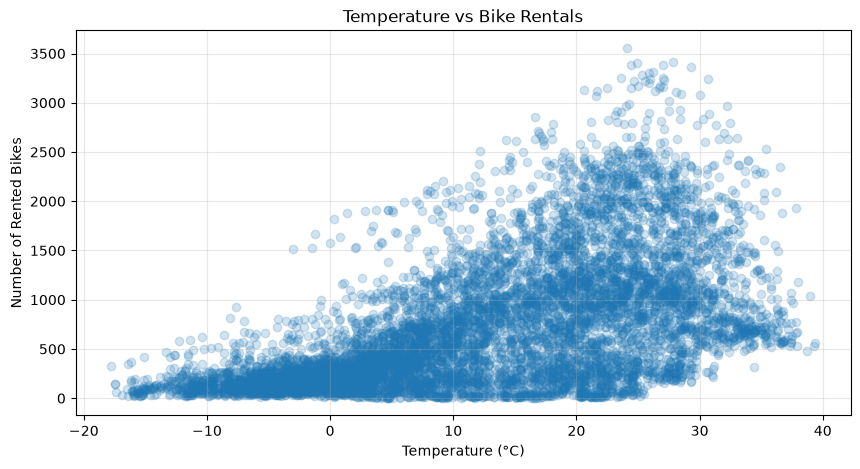

In [25]:

# Create a scatterplot to examine temperature and bike rentals
plt.figure(figsize=(10, 5))

# Each point represents one hour of bike rentals
plt.scatter(
    df_model["Temperature(°C)"],   # X-axis: temperature
    df_model["Rented Bike Count"], # Y-axis: rented bikes
    alpha=0.2                     # Make points transparent to show overlapping observations
)

# Add chart title and labels
plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of Rented Bikes")

# Add a grid
plt.grid(alpha=0.3)

# Display the chart
plt.show()


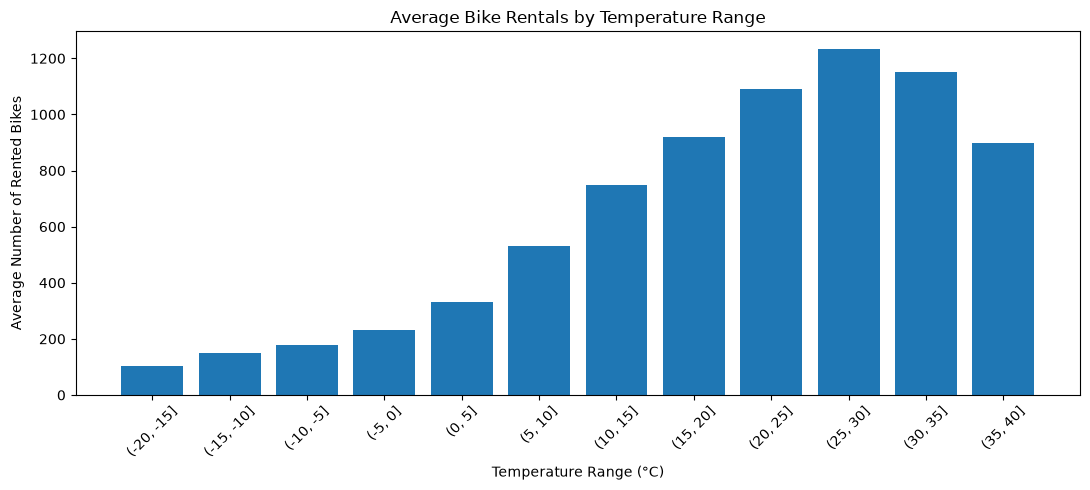

In [26]:

# Create temperature intervals of 5 degrees
temperature_bins = range(-20, 45, 5)

# Group temperatures into intervals
df_model["temperature_group"] = pd.cut(
    df_model["Temperature(°C)"],  # Temperature values
    bins=temperature_bins         # Intervals of 5 degrees
)

# Calculate average bike rentals for each temperature interval
temperature_rentals = (
    df_model.groupby("temperature_group", observed=True)["Rented Bike Count"]
    .mean()
)

# Create a bar chart
plt.figure(figsize=(11, 5))

# Plot average rentals for each temperature group
plt.bar(
    temperature_rentals.index.astype(str),
    temperature_rentals.values
)

# Add chart title and labels
plt.title("Average Bike Rentals by Temperature Range")
plt.xlabel("Temperature Range (°C)")
plt.ylabel("Average Number of Rented Bikes")

# Rotate labels for readability
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()


In [27]:

# Group the data by temperature interval
temperature_summary = df_model.groupby(
    "temperature_group",
    observed=True
)["Rented Bike Count"].agg(
    count="count",  # Number of hourly observations in each interval
    mean="mean",    # Average number of rented bikes
    median="median" # Middle value, less sensitive to extreme values
)

# Round the results to one decimal place
temperature_summary.round(1)


,count,mean,median
temperature_group,,,
"(-20, -15]",46,104.7,76.5
"(-15, -10]",182,150.7,120.5
"(-10, -5]",482,177.2,158.5
"(-5, 0]",744,231.8,198.5
"(0, 5]",1064,330.3,277.0
"(5, 10]",1053,530.6,455.0
"(10, 15]",942,749.8,727.5
"(15, 20]",1116,919.3,891.5
"(20, 25]",1345,1089.1,1025.0


**EDA Finding – Temperature and Rental Demand**

Average bike rental demand increases with temperature up to the 25–30°C interval, where the highest mean (1,234.6 rentals/hour) and median (1,110 rentals/hour) are observed.

Above 30°C, both mean and median rentals decrease, suggesting a potentially nonlinear relationship between temperature and rental demand.

The hottest temperature interval (35–40°C) contains only 89 observations, so its results should be interpreted with caution.

These findings support comparing Linear Regression and Random Forest, as the latter can capture nonlinear relationships. However, temperature is not necessarily the cause of the observed differences, since other factors such as season and hour of day may influence demand.

## 3.6 Monthly Rental Patterns

We examine average hourly bike rentals across the observation period to identify seasonal patterns and changes in demand over time.

These patterns are relevant when choosing a chronological train/test split and evaluating how well the models generalize to future observations.

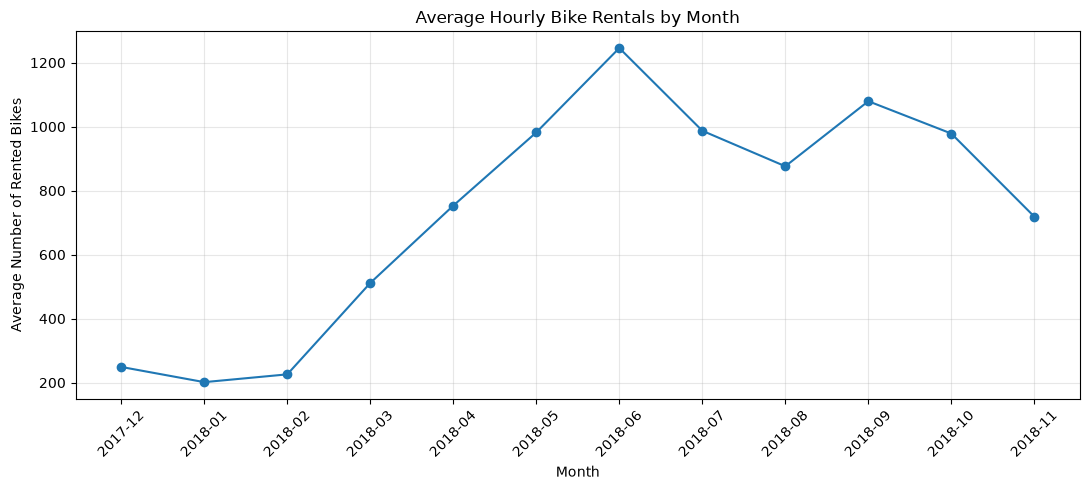

In [28]:

# Extract the year and month from each timestamp
# Example: 2018-06-19 becomes "2018-06"
df_model["year_month"] = df_model["datetime"].dt.to_period("M")

# Calculate average hourly rentals for each month
monthly_rentals = (
    df_model.groupby("year_month")["Rented Bike Count"]
    .mean()
)

# Create a line chart
plt.figure(figsize=(11, 5))

# Plot the monthly averages in chronological order
plt.plot(
    monthly_rentals.index.astype(str),
    monthly_rentals.values,
    marker="o"
)

# Add chart information
plt.title("Average Hourly Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Number of Rented Bikes")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

# Display the chart
plt.tight_layout()
plt.show()


**EDA Finding – Monthly Rental Patterns**

Bike rental demand shows a clear seasonal pattern. Average hourly rentals are lowest during winter (December–February), increase during spring, and reach their highest level in June.

Demand decreases in July and August before rising again in September. This suggests that seasonal factors may be important predictors of bike rental demand.

The dataset covers only one year (December 2017–November 2018), so it is not possible to verify whether these patterns repeat across multiple years.

A chronological train/test split will be used to avoid training on future observations. Time-series cross-validation will also be considered to evaluate model performance across different time periods.


# 4. Feature Engineering and Preprocessing

This section prepares the dataset for machine learning by creating relevant features, selecting input variables, and transforming the data into a suitable format for model training.

New features are derived from existing date and time information. The dataset is then split chronologically into training and test sets to evaluate model performance on later observations.

Missing values and categorical variables are handled through preprocessing pipelines, ensuring that transformations are learned from the training data without introducing data leakage.

##  4.1 Prepare the Modeling Dataset

The purpose of this step is to prepare the dataset for machine learning.

Only observations from operational days (`Functioning Day = Yes`) are included, since the objective is to predict bike rental demand when the bike-sharing system is available.

The observations are sorted chronologically to support time-based model evaluation. Suspicious zero humidity readings are also replaced with missing values, which will be handled during preprocessing to avoid data leakage.


In [29]:

# Create a separate DataFrame for machine learning
model_df = df[df["Functioning Day"] == "Yes"].copy()

# Sort the observations chronologically
model_df = model_df.sort_values("datetime").reset_index(drop=True)

# Replace suspicious zero humidity readings with missing values
# We will handle these missing values during preprocessing
model_df["Humidity(%)"] = model_df["Humidity(%)"].replace(0, np.nan)

# Check the number of rows and columns
print("Shape:", model_df.shape)

# Check how many humidity values are missing
print("Missing humidity values:", model_df["Humidity(%)"].isna().sum())


Shape: (8465, 16)
Missing humidity values: 17



## 4.2 Create Time-Based Features

Exploratory data analysis showed that bike rental demand varies
across hours, weekdays, and seasons.

Two additional features are created:
- `month`: The month of the observation (1–12).
- `is_weekend`: Indicates whether the observation occurred on a weekend.

These features may help the models identify temporal patterns
in bike rental demand.


In [30]:

# Extract the month from the datetime column (1 = January, 12 = December)
model_df["month"] = model_df["datetime"].dt.month

# Extract the day of the week (0 = Monday, 6 = Sunday)
model_df["day_of_week"] = model_df["datetime"].dt.dayofweek

# Create a weekend indicator: 1 = Saturday/Sunday, 0 = Monday–Friday
model_df["is_weekend"] = (model_df["day_of_week"] >= 5).astype(int)

# Display the new features alongside the original datetime
print(model_df[["datetime", "month", "day_of_week", "is_weekend"]].head(10))

# Check the updated number of rows and columns
print("Shape:", model_df.shape)


             datetime  month  day_of_week  is_weekend
0 2017-12-01 00:00:00     12            4           0
1 2017-12-01 01:00:00     12            4           0
2 2017-12-01 02:00:00     12            4           0
3 2017-12-01 03:00:00     12            4           0
4 2017-12-01 04:00:00     12            4           0
5 2017-12-01 05:00:00     12            4           0
6 2017-12-01 06:00:00     12            4           0
7 2017-12-01 07:00:00     12            4           0
8 2017-12-01 08:00:00     12            4           0
9 2017-12-01 09:00:00     12            4           0
Shape: (8465, 19)



## 4.3 Feature Selection

The target variable is `Rented Bike Count`.

Predictor variables are selected based on the EDA findings and their
relevance to hourly bike rental demand.

Cloud cover will initially be excluded from the baseline model and
evaluated separately to measure the contribution of external data.

The target variable and non-predictive identifiers are excluded
to prevent inappropriate model inputs.


In [31]:

# Define the target variable (what we want to predict)
target = "Rented Bike Count"

# Define the initial predictor variables
feature_columns = [
    "Hour",
    "month",
    "is_weekend",
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Rainfall(mm)",
    "Snowfall (cm)",
    "Solar Radiation (MJ/m2)",
    "Holiday"
]

# Create X containing the selected features
X = model_df[feature_columns].copy()

# Create y containing the target values
y = model_df[target].copy()

# Display the first five rows of X
display(X.head())

# Check the dimensions of X and y
print("X shape:", X.shape)
print("y shape:", y.shape)


,Hour,month,is_weekend,Temperature(°C),Humidity(%),Wind speed (m/s),Rainfall(mm),Snowfall (cm),Solar Radiation (MJ/m2),Holiday
0,0,12,0,-5.2,37.0,2.2,0.0,0.0,0.0,No Holiday
1,1,12,0,-5.5,38.0,0.8,0.0,0.0,0.0,No Holiday
2,2,12,0,-6.0,39.0,1.0,0.0,0.0,0.0,No Holiday
3,3,12,0,-6.2,40.0,0.9,0.0,0.0,0.0,No Holiday
4,4,12,0,-6.0,36.0,2.3,0.0,0.0,0.0,No Holiday


X shape: (8465, 10)
y shape: (8465,)



## 4.4 Chronological Train/Test Split

The dataset is divided chronologically into 80% training data
and 20% test data.

A chronological split is used because the observations represent
hourly time-series data. Random splitting could allow the model
to learn from future observations when predicting earlier periods.

All preprocessing steps that learn parameters from the data
will be fitted on the training set only.


In [32]:

# Calculate the position where the training data ends
split_index = int(len(X) * 0.8)

# Select the first 80% of observations for training (iloc based on position not index)
X_train = X.iloc[:split_index].copy()
y_train = y.iloc[:split_index].copy()

# Select the remaining 20% for testing
X_test = X.iloc[split_index:].copy()
y_test = y.iloc[split_index:].copy()

# Display the dimensions of each dataset
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Display the corresponding date ranges
print("\nTraining period:",
      model_df["datetime"].iloc[0],
      "to",
      model_df["datetime"].iloc[split_index - 1])

print("Test period:",
      model_df["datetime"].iloc[split_index],
      "to",
      model_df["datetime"].iloc[-1])


X_train: (6772, 10)
X_test: (1693, 10)
y_train: (6772,)
y_test: (1693,)

Training period: 2017-12-01 00:00:00 to 2018-09-11 03:00:00
Test period: 2018-09-11 04:00:00 to 2018-11-30 23:00:00



## 4.5 Preprocessing

The dataset contains missing humidity values and a categorical
feature (`Holiday`) that must be converted into numerical values.

A preprocessing pipeline is created to:
- Replace missing numerical values using the median.
- Encode categorical variables using one-hot encoding.
- Prevent data leakage by fitting preprocessing only on training data.

The same preprocessing steps will be applied consistently
during model training, cross-validation, and testing.


In [33]:

# Replace missing values using a statistical strategy
from sklearn.impute import SimpleImputer

# Convert categorical values into numerical columns
from sklearn.preprocessing import OneHotEncoder

# Apply different preprocessing steps to different columns
from sklearn.compose import ColumnTransformer

# Combine preprocessing steps and ML models into one workflow
from sklearn.pipeline import Pipeline


In [34]:

# Select all numerical features
numeric_features = [
    "Hour",
    "month",
    "is_weekend",
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Rainfall(mm)",
    "Snowfall (cm)",
    "Solar Radiation (MJ/m2)"
]

# Select categorical features
categorical_features = ["Holiday"]

# Create a pipeline that replaces missing numerical values with the median
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Create a pipeline that converts text categories into numerical columns
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each feature group
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Display the preprocessing configuration
print(preprocessor)


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Hour', 'month', 'is_weekend',
                                  'Temperature(°C)', 'Humidity(%)',
                                  'Wind speed (m/s)', 'Rainfall(mm)',
                                  'Snowfall (cm)', 'Solar Radiation (MJ/m2)']),
                                ('cat',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Holiday'])])



# 5. Model Training

Two supervised regression models will be evaluated:
Linear Regression and Random Forest Regressor.

Linear Regression is used as the initial baseline model.
Random Forest will then be trained to investigate whether a
nonlinear model can better capture patterns in bike rental demand.

Both models will use the same chronological training data
and preprocessing approach to support a fair comparison.

## 5.1 Linear Regression – Baseline Model


In [35]:

# Import the Linear Regression algorithm from scikit-learn
from sklearn.linear_model import LinearRegression


In [36]:

# Create a pipeline combining preprocessing and Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train the model using only the training data
linear_model.fit(X_train, y_train)

# Confirm that the model has been trained
print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!



## 5.2 Random Forest Regressor

Random Forest is an ensemble learning method that combines multiple decision trees to make predictions.

A decision tree works by learning a series of rules from historical data. For example, it may learn that bike rentals tend to be higher during certain hours, when temperatures are comfortable, or when there is little rainfall.

Instead of relying on a single decision tree, Random Forest builds many trees using different samples of the training data and different selections of features. Each tree predicts the expected number of bike rentals, and the final prediction is calculated by averaging their results.

**What does the model learn?**

The model learns patterns between the input features (such as hour, temperature, humidity, and rainfall) and the observed number of bike rentals.

It can also learn interactions between features. For example, the effect of temperature may differ depending on the time of day.

Unlike Linear Regression, Random Forest can capture nonlinear relationships without requiring us to specify these relationships in advance.

**Explanation for a non-technical audience**

Imagine asking 100 different analysts to estimate how many bicycles will be rented at 6 PM on a warm weekday. Each analyst studies slightly different examples from previous rental records and makes an estimate.

Random Forest works in a similar way: it combines predictions from many decision trees to produce a more stable estimate.

The model will be trained using the same training data and preprocessing approach as the Linear Regression baseline.

In [37]:
# Import the Random Forest regression algorithm
from sklearn.ensemble import RandomForestRegressor

In [38]:

# Create a pipeline combining preprocessing and Random Forest
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,    # Build 100 decision trees
        random_state=42,    # Make results reproducible
        n_jobs=-1           # Use available CPU cores
    ))
])

# Train Random Forest using only the training data
random_forest_model.fit(X_train, y_train)

# Confirm successful training
print("Random Forest model trained successfully!")


Random Forest model trained successfully!



# 6. Cross-Validation and Model Evaluation

## 6.1 Time-Series Cross-Validation

TimeSeriesSplit is used to evaluate both regression models across
five chronological validation periods.

Each model is trained on earlier observations and evaluated on
later observations. The training window expands with each fold.

The final test dataset remains untouched during cross-validation.

Model performance will be compared using MAE, RMSE, R² and MAPE.


In [39]:

# Create chronological cross-validation folds
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# Use a separate copy of each pipeline during validation
from sklearn.base import clone


In [40]:

# Create five chronological validation splits
tscv = TimeSeriesSplit(n_splits=5)

# Define the evaluation metrics
# Scikit-learn returns negative values for error metrics
# because higher scores are preferred internally
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error"
}

# Store both models in a dictionary
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

# Create an empty list to store the results
cv_results = []

# Evaluate each model using the same five time-series splits
for name, model in models.items():

    # Train and validate a fresh copy of the model in each fold
    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=tscv,
        scoring=scoring,
        n_jobs=1
    )

    # Calculate the average score across the five folds
    cv_results.append({
        "Model": name,
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean(),
        "MAPE (%)": -scores["test_MAPE"].mean() * 100
    })

# Convert the results into a DataFrame
cv_comparison = pd.DataFrame(cv_results)

# Display the results rounded to two decimal places
display(cv_comparison.round(2))


,Model,MAE,RMSE,R2,MAPE (%)
0,Linear Regression,382.99,488.68,0.21,150.78
1,Random Forest,204.17,290.38,0.69,85.13



## 6.2 Model Performance Comparison

The cross-validation results are visualized to compare
the prediction errors of Linear Regression and Random Forest.

MAE measures the average absolute prediction error, while
RMSE gives greater weight to larger prediction errors.

Lower values indicate better performance for both metrics.


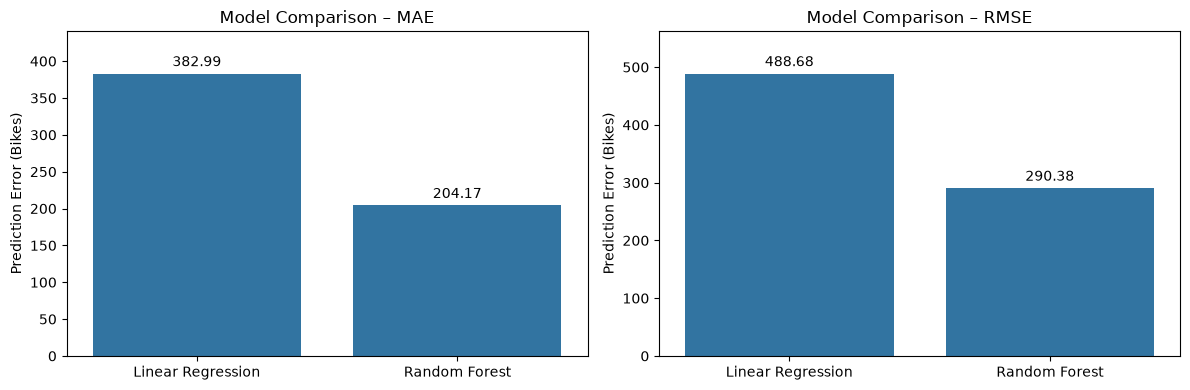

In [41]:

# Select the error metrics we want to visualize
metrics = ["MAE", "RMSE"]

# Create two charts next to each other
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loop through MAE and RMSE
for i, metric in enumerate(metrics):

    # Create a bar chart for the current metric
    sns.barplot(
        data=cv_comparison,
        x="Model",
        y=metric,
        ax=axes[i]
    )

    # Add a title for each chart
    axes[i].set_title(f"Model Comparison – {metric}")

    # Label the vertical axis
    axes[i].set_ylabel("Prediction Error (Bikes)")

    # Remove the horizontal axis label
    axes[i].set_xlabel("")

    # Add the exact value above each bar
    for container in axes[i].containers:

        # Display each value with two decimal places
        axes[i].bar_label(
            container,
            fmt="%.2f",
            padding=3
        )

    # Add 15% extra space above the tallest bar
    axes[i].set_ylim(0, cv_comparison[metric].max() * 1.15)

# Adjust spacing so charts do not overlap
plt.tight_layout()

# Display the charts
plt.show()



**Model Evaluation Finding – Baseline vs Random Forest**

Random Forest outperformed Linear Regression across all five-fold
cross-validation metrics.

Random Forest achieved a mean MAE of 204.17 bikes compared with
382.99 for Linear Regression, representing approximately 47%
lower average absolute prediction error.

RMSE decreased from 488.68 to 290.38 bikes, suggesting that
Random Forest also handles larger prediction errors better.

These results indicate that nonlinear relationships are important
for predicting hourly bike rental demand.

However, performance on the final held-out test period has not
yet been evaluated.



## 6.3 Cross-Validation Performance Across Folds

The average cross-validation scores provide an overall comparison,
but they may hide differences between validation periods.

The MAE for each fold is visualized to examine how consistently
the models perform across different time periods.


In [42]:

# Create an empty list to store the results for each fold
fold_results = []

# Loop through both models
for name, model in models.items():

    # Perform cross-validation and collect the scores
    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    # Loop through the five MAE scores
    for fold, mae in enumerate(scores["test_score"], start=1):

        # Save the model name, fold number and positive MAE
        fold_results.append({
            "Model": name,
            "Fold": fold,
            "MAE": -mae
        })

# Convert the results into a DataFrame
fold_df = pd.DataFrame(fold_results)

# Display the individual fold results
display(fold_df.round(2))


,Model,Fold,MAE
0,Linear Regression,1,85.60
1,Linear Regression,2,324.50
2,Linear Regression,3,476.43
3,Linear Regression,4,503.30
4,Linear Regression,5,525.11
5,Random Forest,1,58.79
6,Random Forest,2,228.06
7,Random Forest,3,333.11
8,Random Forest,4,230.08
9,Random Forest,5,170.83


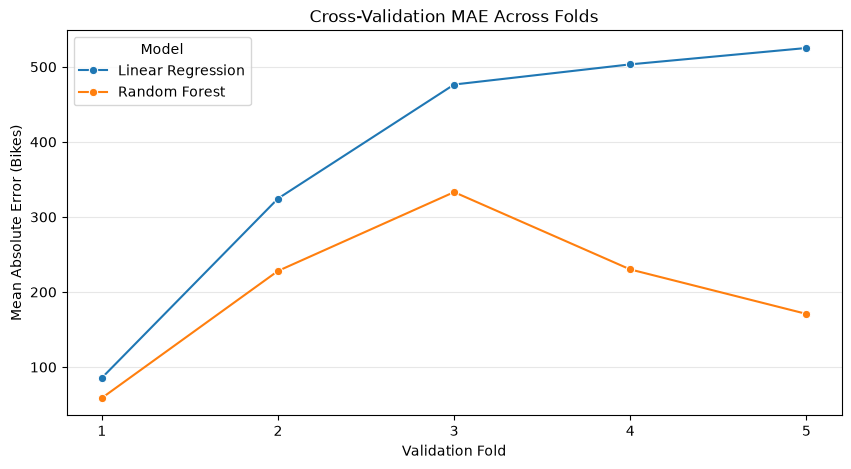

In [43]:

# Create a line chart showing MAE for each validation fold
plt.figure(figsize=(10, 5))

# Draw one line for each model
sns.lineplot(
    data=fold_df,
    x="Fold",
    y="MAE",
    hue="Model",
    marker="o"
)

# Add title and axis labels
plt.title("Cross-Validation MAE Across Folds")
plt.xlabel("Validation Fold")
plt.ylabel("Mean Absolute Error (Bikes)")

# Show only fold numbers 1 to 5 on the X-axis
plt.xticks([1, 2, 3, 4, 5])

# Add horizontal gridlines to make comparisons easier
plt.grid(axis="y", alpha=0.3)

# Display the chart
plt.show()



**Cross-Validation Finding – Model Stability**

Random Forest achieved a lower MAE than Linear Regression
in all five validation folds.

Linear Regression showed a consistent increase in MAE,
from 85.60 bikes in fold 1 to 525.11 bikes in fold 5.

Random Forest also showed variation across folds, with
its highest MAE in fold 3 (333.11 bikes), followed by
improved performance in folds 4 and 5.

These differences may reflect changes in rental demand,
weather conditions and seasonal patterns over time.

Further analysis is needed to determine why model
performance varies between validation periods.


In [44]:

# Create an empty list to store information about each fold
fold_periods = []

# Loop through the five chronological training/validation splits
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    # Get the first and last dates in the validation period
    validation_start = model_df.loc[X_train.index[val_idx[0]], "datetime"]
    validation_end = model_df.loc[X_train.index[val_idx[-1]], "datetime"]

    # Calculate average actual rentals during validation
    average_rentals = y_train.iloc[val_idx].mean()

    # Save the information for this fold
    fold_periods.append({
        "Fold": fold,
        "Validation Start": validation_start,
        "Validation End": validation_end,
        "Average Rentals": average_rentals
    })

# Convert the results into a DataFrame
fold_periods_df = pd.DataFrame(fold_periods)

# Round only the numeric column
fold_periods_df["Average Rentals"] = fold_periods_df["Average Rentals"].round(2)

# Display the complete DataFrame
display(fold_periods_df)


,Fold,Validation Start,Validation End,Average Rentals
0,1,2018-01-17 04:00:00,2018-03-05 03:00:00,218.89
1,2,2018-03-05 04:00:00,2018-04-22 03:00:00,616.03
2,3,2018-04-22 04:00:00,2018-06-09 03:00:00,1016.61
3,4,2018-06-09 04:00:00,2018-07-26 03:00:00,1102.66
4,5,2018-07-26 04:00:00,2018-09-11 03:00:00,933.51


In [45]:

# Combine the MAE results with the average rental demand per fold
fold_analysis = fold_df.merge(
    fold_periods_df[["Fold", "Average Rentals"]],
    on="Fold"
)

# Calculate MAE relative to average rental demand
fold_analysis["Relative MAE (%)"] = (
    fold_analysis["MAE"] / fold_analysis["Average Rentals"] * 100
)

# Display the comparison
display(fold_analysis.round(2))


,Model,Fold,MAE,Average Rentals,Relative MAE (%)
0,Linear Regression,1,85.60,218.89,39.11
1,Linear Regression,2,324.50,616.03,52.68
2,Linear Regression,3,476.43,1016.61,46.87
3,Linear Regression,4,503.30,1102.66,45.64
4,Linear Regression,5,525.11,933.51,56.25
5,Random Forest,1,58.79,218.89,26.86
6,Random Forest,2,228.06,616.03,37.02
7,Random Forest,3,333.11,1016.61,32.77
8,Random Forest,4,230.08,1102.66,20.87
9,Random Forest,5,170.83,933.51,18.30



**Cross-Validation Finding – Seasonal Demand and Relative Error**

The validation periods show substantial differences in average
hourly rental demand, ranging from approximately 219 bikes in
fold 1 to 1,103 bikes in fold 4.

Absolute prediction errors tend to be larger during periods
with higher rental demand.

However, when MAE is normalized by average rental demand,
Random Forest shows lower relative errors in the later folds.

This suggests that model performance should be evaluated
in relation to demand levels, rather than relying only on
absolute error metrics.

The results also indicate that training history and seasonal
changes may influence model performance.


### Model Selection and Trade-Offs

Random Forest was selected as the final model because it consistently outperformed Linear Regression across all five time-series cross-validation folds.

The average validation MAE was 204.17 bikes for Random Forest, compared with 382.99 bikes for Linear Regression. This represents approximately 47% lower average absolute prediction error.

Random Forest is better suited to this problem because bike rental demand is influenced by nonlinear relationships and interactions between time and weather conditions.

**Trade-offs**

The improved predictive performance comes with several limitations:

- **Interpretability:** Linear Regression provides coefficients that are relatively easy to explain, while Random Forest combines many decision trees and is more difficult to interpret directly.
- **Computational complexity:** Random Forest requires more computation and memory for training and prediction.
- **Extrapolation:** Random Forest generally struggles to predict values outside the range represented in its training data, which can be a limitation during unusually high-demand periods.

Despite these trade-offs, Random Forest was chosen because its substantially lower prediction errors make it more useful for estimating hourly bike rental demand.

The final model is evaluated on the held-out test period in Section 9.


# 7. Model Improvement

## 7.1 Adding Cloud Cover as an External Feature

The baseline Random Forest model was trained using ten input features.

This experiment evaluates whether adding cloud cover data from
Open-Meteo improves the model's predictive performance.

Both versions will use the same chronological training data,
cross-validation strategy and model parameters.

The goal is to measure the additional predictive value of
the external weather feature.


In [46]:

# Display all column names in our modeling DataFrame
print(model_df.columns.tolist())

# Check which column names contain the word "cloud"
cloud_columns = [
    col for col in model_df.columns
    if "cloud" in col.lower()
]

# Display the matching columns
print("Cloud cover columns:", cloud_columns)


['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day', 'datetime', 'cloud_cover', 'month', 'day_of_week', 'is_weekend']
Cloud cover columns: ['cloud_cover']


In [47]:

# Create a new feature list with cloud cover added
feature_columns_cloud = feature_columns + ["cloud_cover"]

# Select the same observations as our original training data
X_cloud = model_df[feature_columns_cloud].copy()

# Use the same chronological split as the baseline model
X_cloud_train = X_cloud.iloc[:split_index].copy()
X_cloud_test = X_cloud.iloc[split_index:].copy()

# Add cloud cover to the existing numeric features
numeric_features_cloud = numeric_features + ["cloud_cover"]

# Create a new preprocessor for the extended feature set
preprocessor_cloud = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features_cloud),
    ("cat", categorical_transformer, categorical_features)
])

# Create a Random Forest pipeline with the additional feature
random_forest_cloud = Pipeline(steps=[
    ("preprocessor", preprocessor_cloud),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Check the number of input features
print("Original features:", X_train.shape[1])
print("Features with cloud cover:", X_cloud_train.shape[1])

# Check that both versions have the same number of training rows
print("Original training rows:", len(X_train))
print("Cloud training rows:", len(X_cloud_train))


Original features: 10
Features with cloud cover: 11
Original training rows: 6772
Cloud training rows: 6772



## 7.1.1 Cross-Validation – Cloud Cover Experiment

The extended Random Forest model is evaluated using the same
five-fold TimeSeriesSplit as the original model.

All model parameters remain unchanged. The only difference
is the addition of the external cloud cover feature.

MAE, RMSE and R² are compared to evaluate whether the
additional feature improves predictive performance.


In [48]:

# Evaluate Random Forest with the additional cloud cover feature
cloud_scores = cross_validate(
    clone(random_forest_cloud),  # Create a fresh copy of the model
    X_cloud_train,              # Training data with 11 features
    y_train,                    # Actual rental counts
    cv=tscv,                    # Same five chronological validation folds
    scoring=scoring,            # Same evaluation metrics as before
    n_jobs=1                    # Run the validation folds sequentially
)

# Calculate the average scores across the five folds
cloud_results = {
    "Model": "Random Forest + Cloud Cover",
    "MAE": -cloud_scores["test_MAE"].mean(),
    "RMSE": -cloud_scores["test_RMSE"].mean(),
    "R2": cloud_scores["test_R2"].mean(),
    "MAPE (%)": -cloud_scores["test_MAPE"].mean() * 100
}

# Select the original Random Forest results for comparison
original_rf_results = cv_comparison[
    cv_comparison["Model"] == "Random Forest"
]

# Combine the original and extended model results
cloud_comparison = pd.concat(
    [original_rf_results, pd.DataFrame([cloud_results])],
    ignore_index=True
)

# Display the comparison
display(cloud_comparison.round(2))


,Model,MAE,RMSE,R2,MAPE (%)
0,Random Forest,204.17,290.38,0.69,85.13
1,Random Forest + Cloud Cover,204.78,290.89,0.69,84.82



**Model Improvement Finding – Cloud Cover Experiment**

Adding cloud cover as an external weather feature did not
improve the overall predictive performance of Random Forest.

MAE increased slightly from 204.17 to 204.78 bikes, while
RMSE increased from 290.38 to 290.89 bikes.

R² remained approximately unchanged at 0.69, while MAPE
decreased slightly from 85.13% to 84.82%.

The results suggest that cloud cover provides limited
additional predictive value when the existing weather
and time-related features are already included.

The original Random Forest model is therefore retained
for further experimentation.



## 7.2 Adding Day of Week as a Feature

EDA showed differences in hourly bike rental patterns
across weekdays and weekends.

The original Random Forest model includes is_weekend
but does not distinguish between individual weekdays.

This experiment tests whether adding day_of_week improves
prediction accuracy.

The same chronological training data, cross-validation
strategy and Random Forest parameters will be used.


In [49]:

# Add day_of_week to the original feature list
feature_columns_weekday = feature_columns + ["day_of_week"]

# Create a dataset including the additional feature
X_weekday = model_df[feature_columns_weekday].copy()

# Use the same chronological training split
X_weekday_train = X_weekday.iloc[:split_index].copy()
X_weekday_test = X_weekday.iloc[split_index:].copy()

# Treat day_of_week as a categorical feature
categorical_features_weekday = categorical_features + ["day_of_week"]

# Create preprocessing for the weekday experiment
preprocessor_weekday = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features_weekday)
])

# Create a Random Forest pipeline with the additional feature
random_forest_weekday = Pipeline(steps=[
    ("preprocessor", preprocessor_weekday),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Confirm that the model pipeline has been created
print("Random Forest with day_of_week created successfully!")


Random Forest with day_of_week created successfully!


In [50]:

# Evaluate Random Forest with day_of_week added
weekday_scores = cross_validate(
    clone(random_forest_weekday),  # Create a fresh copy of the model
    X_weekday_train,              # Training data with 11 input features
    y_train,                      # Actual bike rental counts
    cv=tscv,                      # Same five chronological validation folds
    scoring=scoring,              # MAE, RMSE, R2 and MAPE
    n_jobs=1                      # Run one validation fold at a time
)

# Calculate average evaluation metrics across all five folds
weekday_results = {
    "Model": "Random Forest + Day of Week",
    "MAE": -weekday_scores["test_MAE"].mean(),
    "RMSE": -weekday_scores["test_RMSE"].mean(),
    "R2": weekday_scores["test_R2"].mean(),
    "MAPE (%)": -weekday_scores["test_MAPE"].mean() * 100
}

# Combine results from the original Random Forest and both experiments
experiment_comparison = pd.concat(
    [
        cv_comparison[cv_comparison["Model"] == "Random Forest"],
        cloud_comparison[
            cloud_comparison["Model"] == "Random Forest + Cloud Cover"
        ],
        pd.DataFrame([weekday_results])
    ],
    ignore_index=True
)

# Display the results
display(experiment_comparison.round(2))


,Model,MAE,RMSE,R2,MAPE (%)
0,Random Forest,204.17,290.38,0.69,85.13
1,Random Forest + Cloud Cover,204.78,290.89,0.69,84.82
2,Random Forest + Day of Week,204.42,289.77,0.69,87.10



**Model Improvement Finding, Day of Week Experiment**

Adding day_of_week did not produce a meaningful overall
improvement in Random Forest performance.

MAE increased slightly from 204.17 to 204.42 bikes,
while RMSE decreased from 290.38 to 289.77 bikes.

R² remained approximately unchanged at 0.69, while
MAPE increased from 85.13% to 87.10%.

The results suggest that the existing Hour and is_weekend
features may already capture much of the relevant
weekly rental pattern.

The original Random Forest model is retained for
further experimentation.



## 7.3 Random Forest Hyperparameter Tuning

This experiment investigates how limiting tree depth
affects Random Forest prediction performance.

Different max_depth values are compared using the same
five-fold time-series cross-validation.

The goal is to find a balance between model complexity
and generalization performance without using the final test set.


In [51]:

# Different maximum tree depths to evaluate
depth_values = [3, 5, 10, 15, 20, None]

# Create an empty list to store the results
depth_results = []

# Test one maximum depth at a time
for depth in depth_values:

    # Create a new Random Forest model with the selected depth
    depth_model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Evaluate the model using the same five time-series folds
    scores = cross_validate(
        depth_model,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    # Save the average MAE for this depth
    depth_results.append({
        "max_depth": str(depth),
        "MAE": -scores["test_score"].mean()
    })

# Convert the results into a DataFrame
depth_comparison = pd.DataFrame(depth_results)

# Display the results
display(depth_comparison.round(2))


,max_depth,MAE
0,3,300.88
1,5,259.46
2,10,209.08
3,15,204.47
4,20,203.88
5,None,204.17


In [52]:

# Compare training and validation errors for different tree depths
overfitting_results = []

# Test each maximum tree depth
for depth in depth_values:

    # Create a new Random Forest pipeline
    depth_model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=depth,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Calculate both training and validation MAE
    scores = cross_validate(
        depth_model,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
        n_jobs=1
    )

    # Store the average errors across the five folds
    overfitting_results.append({
        "max_depth": str(depth),
        "Train MAE": -scores["train_score"].mean(),
        "Validation MAE": -scores["test_score"].mean()
    })

# Create a DataFrame with the results
overfitting_df = pd.DataFrame(overfitting_results)

# Display the results
display(overfitting_df.round(2))


,max_depth,Train MAE,Validation MAE
0,3,138.60,300.88
1,5,105.49,259.46
2,10,47.19,209.08
3,15,26.09,204.47
4,20,23.51,203.88
5,None,23.43,204.17



**Hyperparameter Tuning Finding, Maximum Tree Depth**

Increasing max_depth from 3 to 15 substantially reduced
validation MAE from 300.88 to 204.47 bikes.

Further increases in tree depth produced only marginal
improvements in validation performance, while training
MAE continued to decrease.

This indicates diminishing returns from additional model
complexity and suggests potential overfitting in deeper trees.

A max_depth of 15 was selected as a candidate for further
evaluation, balancing model complexity and validation error.

The final model has not yet been evaluated on the held-out
test dataset.


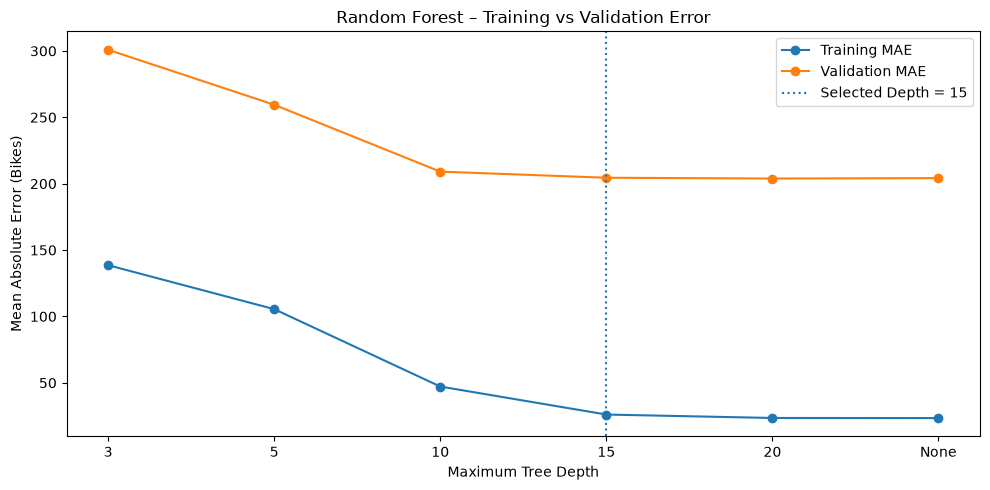

In [53]:

# Convert max_depth to a numeric value for plotting
# None is displayed separately as "Unlimited"
depth_plot = overfitting_df.copy()

# Use positions 0–5 for the six depth settings
x_positions = range(len(depth_plot))

# Create the figure
plt.figure(figsize=(10, 5))

# Plot the average training error
plt.plot(
    x_positions,
    depth_plot["Train MAE"],
    marker="o",
    label="Training MAE"
)

# Plot the average validation error
plt.plot(
    x_positions,
    depth_plot["Validation MAE"],
    marker="o",
    label="Validation MAE"
)

# Display the original depth values on the x-axis
plt.xticks(
    x_positions,
    ["3", "5", "10", "15", "20", "None"]
)

# Mark our selected tree depth
plt.axvline(
    x=3,                 # Position of max_depth=15
    linestyle=":",
    label="Selected Depth = 15"
)

# Add labels and title
plt.title("Random Forest – Training vs Validation Error")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean Absolute Error (Bikes)")

# Display legend and chart
plt.legend()
plt.tight_layout()
plt.show()



**Hyperparameter Tuning Finding, Model Complexity**

Training MAE decreased substantially as tree depth increased,
while validation MAE showed diminishing improvements beyond
a maximum depth of approximately 10–15.

A maximum depth of 15 was selected as a reasonable balance
between model complexity and validation performance.

Although deeper trees achieved slightly lower validation
errors, the improvements were marginal.



## 7.3.1 Minimum Samples per Leaf

This experiment evaluates whether increasing min_samples_leaf
can reduce overfitting and improve validation performance.

The maximum tree depth is fixed at 15, while the minimum
number of samples per leaf is varied.

Both training and validation MAE are compared using
five-fold time-series cross-validation.


In [54]:

# Define the minimum number of observations allowed per leaf
leaf_values = [1, 2, 5, 10, 20]

# Create an empty list to store the results
leaf_results = []

# Test each min_samples_leaf value
for leaf in leaf_values:

    # Create a Random Forest with a fixed maximum depth
    leaf_model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=leaf,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Evaluate both training and validation performance
    scores = cross_validate(
        leaf_model,
        X_train,
        y_train,
        cv=tscv,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
        n_jobs=1
    )

    # Store the average MAE across the five folds
    leaf_results.append({
        "min_samples_leaf": leaf,
        "Train MAE": -scores["train_score"].mean(),
        "Validation MAE": -scores["test_score"].mean()
    })

# Convert results into a DataFrame
leaf_comparison = pd.DataFrame(leaf_results)

# Display the results
display(leaf_comparison.round(2))


,min_samples_leaf,Train MAE,Validation MAE
0,1,26.09,204.47
1,2,32.37,204.97
2,5,50.00,212.14
3,10,64.90,229.96
4,20,81.32,256.63



**Hyperparameter Tuning Finding, Minimum Samples per Leaf**

Increasing min_samples_leaf from 1 to 20 increased both
training and validation MAE.

Validation MAE increased from 204.47 to 256.63 bikes,
indicating that larger minimum leaf sizes reduced model
performance in this experiment.

Although the gap between training and validation error
became smaller, validation performance did not improve.

Therefore, min_samples_leaf=1 was retained as the best
value among those tested.


In [55]:

# Create the selected Random Forest model
final_rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=100,       # Number of trees in the forest
        max_depth=15,           # Maximum depth of each tree
        min_samples_leaf=1,     # Minimum observations in each leaf
        random_state=42,        # Reproducible results
        n_jobs=-1               # Use available CPU cores
    ))
])

# Train the model on the full training dataset
final_rf_model.fit(X_train, y_train)

# Confirm that training is complete
print("Final Random Forest model trained successfully!")


Final Random Forest model trained successfully!


In [64]:
# Import joblib to save trained machine learning models
import joblib

# Save the complete trained pipeline to a file
joblib.dump(final_rf_model, "bikeflow_model.joblib")

# Confirm that the model has been saved
print("Random Forest model saved successfully!")

Random Forest model saved successfully!



# 8. Model Interpretation

## 8.1 Random Forest Feature Importance

Feature importance is used to identify which input variables
contribute most to the Random Forest model's predictions.

The analysis is based on the original Random Forest model
with ten input features, trained on the training dataset.

Feature importance measures the contribution of each feature
to reducing prediction error across the decision trees.

These values do not establish causal relationships.


In [56]:

# Access the trained Random Forest from our final model
rf_model = final_rf_model.named_steps["model"]

# Access the preprocessing fitted with the final model
rf_preprocessor = final_rf_model.named_steps["preprocessor"]

# Get the feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Get the feature importance values from Random Forest
importance_values = rf_model.feature_importances_

# Create a DataFrame combining feature names and importance values
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort the features from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the importance values
display(importance_df.round(4))


,Feature,Importance
3,num__Temperature(°C),0.4127
0,num__Hour,0.2900
8,num__Solar Radiation (MJ/m2),0.0962
4,num__Humidity(%),0.0682
6,num__Rainfall(mm),0.0614
2,num__is_weekend,0.0315
1,num__month,0.0236
5,num__Wind speed (m/s),0.0110
9,cat__Holiday_Holiday,0.0024
10,cat__Holiday_No Holiday,0.0021


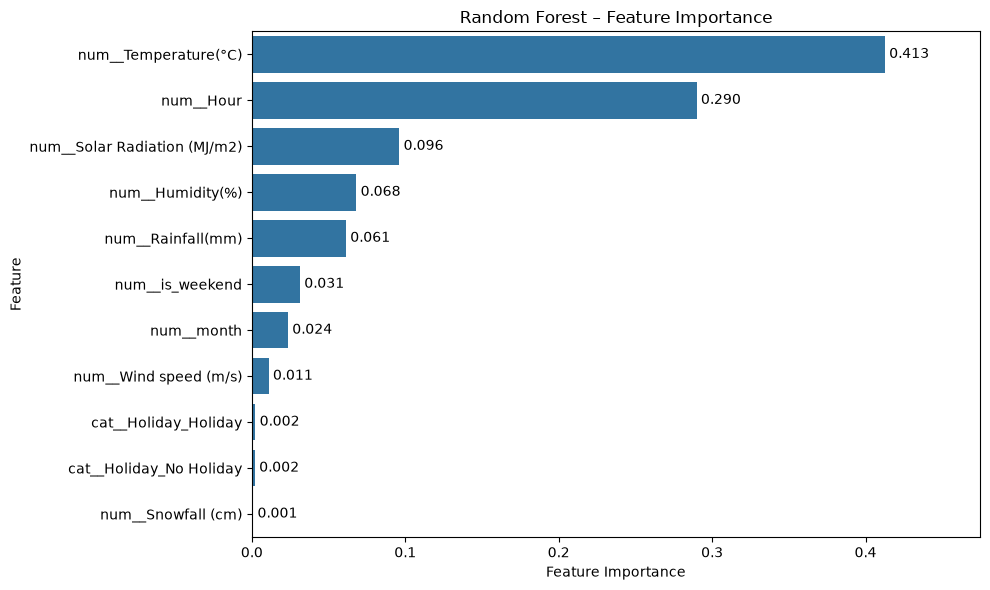

In [57]:

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

# Plot features in descending order of importance
ax = sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

# Add exact importance values at the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

# Add extra space for the value labels
ax.set_xlim(0, importance_df["Importance"].max() * 1.15)

# Add title and axis labels
plt.title("Random Forest – Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()



**Model Interpretation Finding – Feature Importance**

Temperature (0.412) and hour (0.289) are the two most
important features in the Random Forest model, together
accounting for approximately 70% of the total feature importance.

Solar radiation (0.096), humidity (0.069) and rainfall
(0.061) also contribute to the model's predictions.

The weekend indicator has a relatively low importance
(0.031). However, the model does not currently include
the specific day of the week.

This suggests an opportunity for further feature
engineering by adding day_of_week and evaluating its
predictive value through time-series cross-validation.

Feature importance reflects contributions to the model's
tree splits and should not be interpreted as causal effects.



# 9. Final Model Evaluation

The final models are evaluated on the held-out test dataset,
which was not used during model development or hyperparameter tuning.

Linear Regression is compared with the selected Random Forest model
(max_depth=15, min_samples_leaf=1).

The evaluation uses MAE, RMSE and R² to assess how well the models
generalize to unseen observations.


In [58]:

# Predict bike rentals using Linear Regression
linear_test_predictions = linear_model.predict(X_test)

# Predict bike rentals using the final Random Forest
rf_test_predictions = final_rf_model.predict(X_test)

# Display the first five actual and predicted values
prediction_comparison = pd.DataFrame({
    "Actual Rentals": y_test.values,
    "Linear Regression": linear_test_predictions,
    "Random Forest": rf_test_predictions
})

# Show the first five rows
display(prediction_comparison.head())


,Actual Rentals,Linear Regression,Random Forest
0,193,783.747608,220.326469
1,258,772.194161,242.732677
2,678,781.008457,612.408132
3,1556,802.577872,1206.582198
4,2369,834.358566,2087.041157


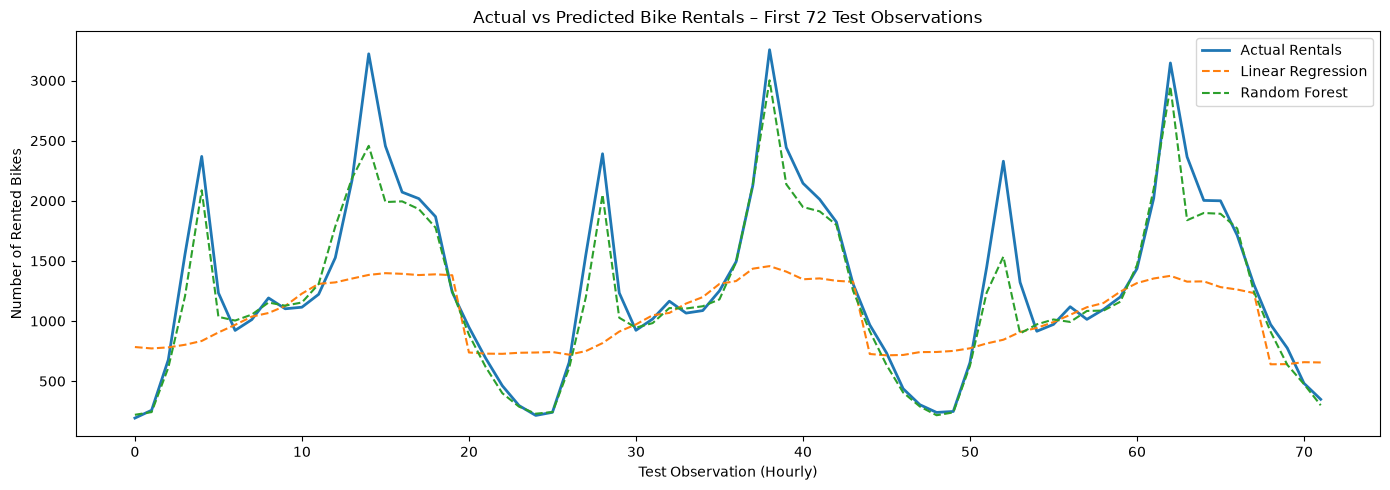

In [59]:

# Select the first 72 observations from the test period
n_hours = 72

# Create a figure
plt.figure(figsize=(14, 5))

# Plot the actual number of rented bikes
plt.plot(
    y_test.iloc[:n_hours].values,
    label="Actual Rentals",
    linewidth=2
)

# Plot Linear Regression predictions
plt.plot(
    linear_test_predictions[:n_hours],
    label="Linear Regression",
    linestyle="--"
)

# Plot Random Forest predictions
plt.plot(
    rf_test_predictions[:n_hours],
    label="Random Forest",
    linestyle="--"
)

# Add labels and a descriptive title
plt.title("Actual vs Predicted Bike Rentals – First 72 Test Observations")
plt.xlabel("Test Observation (Hourly)")
plt.ylabel("Number of Rented Bikes")

# Display the legend and chart
plt.legend()
plt.tight_layout()
plt.show()


In [60]:

# Import metrics for regression model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Store predictions from both models
test_predictions = {
    "Linear Regression": linear_test_predictions,
    "Random Forest": rf_test_predictions
}

# Create an empty list for evaluation results
test_results = []

# Calculate evaluation metrics for each model
for name, predictions in test_predictions.items():

    # Calculate the average absolute prediction error
    mae = mean_absolute_error(y_test, predictions)

    # Calculate RMSE, which penalizes large errors more heavily
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    # Calculate R², comparing the model with a mean prediction
    r2 = r2_score(y_test, predictions)

    # Store the results
    test_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Create a DataFrame for the final test results
test_comparison = pd.DataFrame(test_results)

# Display the results
display(test_comparison.round(2))


,Model,MAE,RMSE,R2
0,Linear Regression,340.52,481.16,0.36
1,Random Forest,219.52,312.52,0.73



## 9.2 Final Model Evaluation Finding

Random Forest outperformed Linear Regression on the held-out
test dataset.

Random Forest achieved a test MAE of 219.52 bikes, compared
with 340.52 bikes for Linear Regression, representing an
approximately 36% reduction in average absolute error.

RMSE decreased from 481.16 to 312.52 bikes, while R²
increased from 0.36 to 0.73.

The actual vs predicted visualization shows that Random
Forest captures hourly demand peaks and daily rental
patterns more effectively than Linear Regression.

However, the model still underestimates some high-demand
periods, which could affect operational capacity planning.



## 9.3 Error Analysis, High-Demand Periods

This analysis investigates whether the Random Forest model
systematically underestimates bike rentals during periods
of high demand.

Understanding prediction errors during peak demand is
important for operational capacity planning, since
underestimating demand may lead to bicycle shortages.


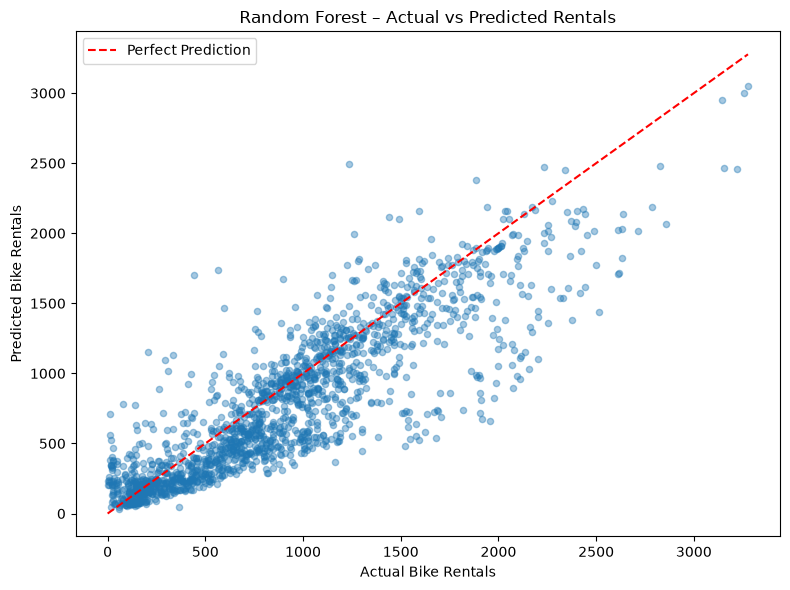

In [61]:

# Create a scatterplot comparing actual and predicted rentals
plt.figure(figsize=(8, 6))

# Plot all test observations
plt.scatter(
    y_test,
    rf_test_predictions,
    alpha=0.4,             # Make points transparent to show overlapping values
    s=20                   # Set the size of the points
)

# Find the maximum value for the reference line
max_value = max(y_test.max(), rf_test_predictions.max())

# Draw a reference line showing perfect predictions
plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    color="red",
    label="Perfect Prediction"
)

# Add labels and title
plt.title("Random Forest – Actual vs Predicted Rentals")
plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")

# Display the legend
plt.legend()

# Display the chart
plt.tight_layout()
plt.show()


In [62]:

# Create a DataFrame with actual and predicted rentals
error_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": rf_test_predictions
})

# Calculate the signed prediction error
# Negative values mean the model underestimated demand
error_df["Error"] = error_df["Predicted"] - error_df["Actual"]

# Calculate the 75th percentile of actual rentals
high_demand_threshold = error_df["Actual"].quantile(0.75)

# Select the 25% of observations with highest actual rentals
high_demand = error_df[
    error_df["Actual"] >= high_demand_threshold
].copy()

# Calculate the average signed error during high demand
mean_error = high_demand["Error"].mean()

# Calculate the percentage of high-demand hours underestimated
underestimated_pct = (
    (high_demand["Error"] < 0).mean() * 100
)

# Calculate MAE for high-demand observations
high_demand_mae = high_demand["Error"].abs().mean()

# Display the results
print(f"High-demand threshold: {high_demand_threshold:.0f} bikes")
print(f"High-demand observations: {len(high_demand)}")
print(f"Mean signed error: {mean_error:.2f} bikes")
print(f"High-demand MAE: {high_demand_mae:.2f} bikes")
print(f"Underestimated high-demand hours: {underestimated_pct:.1f}%")


High-demand threshold: 1233 bikes
High-demand observations: 425
Mean signed error: -272.24 bikes
High-demand MAE: 348.48 bikes
Underestimated high-demand hours: 76.9%


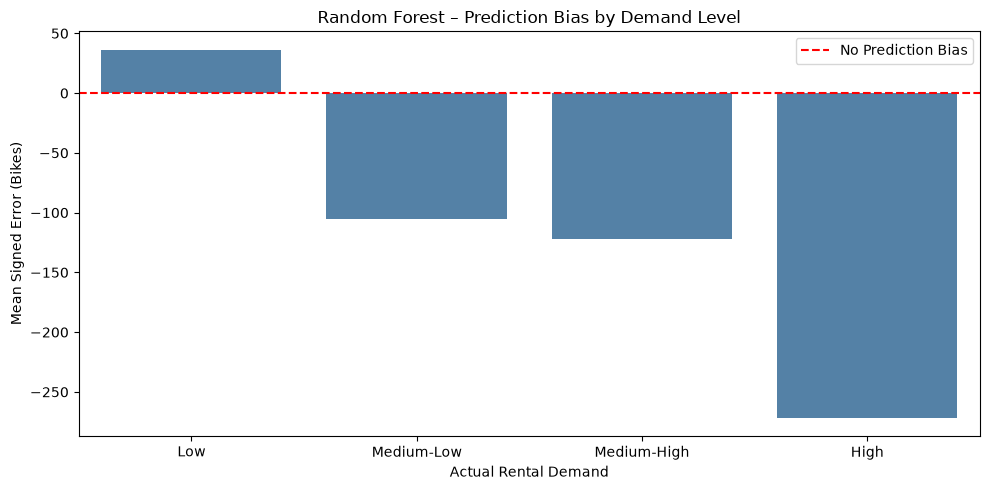

,Demand Group,Error
0,Low,36.27
1,Medium-Low,-105.02
2,Medium-High,-122.12
3,High,-271.54


In [63]:

# Divide actual rental demand into four equally sized groups
error_df["Demand Group"] = pd.qcut(
    error_df["Actual"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

# Calculate average signed prediction error for each group
demand_errors = (
    error_df.groupby("Demand Group", observed=True)["Error"]
    .mean()
    .reset_index()
)

# Create a bar chart
plt.figure(figsize=(10, 5))

# Plot average prediction error by demand group
sns.barplot(
    data=demand_errors,
    x="Demand Group",
    y="Error",
    color="steelblue"
)

# Add a horizontal reference line at zero error
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="No Prediction Bias"
)

# Add labels and title
plt.title("Random Forest – Prediction Bias by Demand Level")
plt.xlabel("Actual Rental Demand")
plt.ylabel("Mean Signed Error (Bikes)")

# Show legend and chart
plt.legend()
plt.tight_layout()
plt.show()

# Display the underlying values for interpretation
display(demand_errors.round(2))



**Error Analysis Finding – Prediction Bias at High Demand**

The Random Forest model shows a clear pattern of increasing
underestimation as actual rental demand rises.

For the highest-demand quartile, the mean signed prediction
error was approximately -272 bikes per hour.

The model underestimated rentals in 76.9% of the high-demand
observations, with an MAE of 348.48 bikes compared with
219.52 bikes across the full test dataset.

Although the model achieved an overall test R² of 0.73,
its performance during peak-demand periods remains a
limitation for operational capacity planning.

These results highlight the importance of evaluating model
performance across different demand levels, rather than
relying only on overall metrics.

